In [1]:
# No installation should be necessary for these libraries in Colab

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [2]:
!pip install -q datasets


In [3]:
from datasets import load_dataset

dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

dataset

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})

In [4]:
df = dataset["train"].to_pandas()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (26872, 5)

Columns:
['flags', 'instruction', 'category', 'intent', 'response']


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


In [6]:
print(df.isnull().sum())

flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [7]:
df.head(10)

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...
5,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling..."
6,BCLN,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order,I pick up what you're putting down that you're...
7,BL,I am trying to cancel purchase {{Order Number}},ORDER,cancel_order,I've understood that you're seeking assistance...
8,BL,I have got to cancel purchase {{Order Number}},ORDER,cancel_order,I'm sensitive to the fact that you're seeking ...
9,BLQ,i need help canceling purchase {{Order Number}},ORDER,cancel_order,I perceive that you're seeking assistance with...


In [9]:
print("Number of intents:", df["intent"].nunique())

print("\nIntent distribution:")
print(df["intent"].value_counts())

Number of intents: 27

Intent distribution:
intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64


In [10]:
print(df.columns.tolist())

['flags', 'instruction', 'category', 'intent', 'response']


In [11]:
TEXT_COLUMN = "instruction"
INTENT_COLUMN = "intent"

df_model = df[[TEXT_COLUMN, INTENT_COLUMN]].copy()

# Remove missing values
df_model = df_model.dropna()

# Remove duplicate examples
df_model = df_model.drop_duplicates()

# Make sure everything is text
df_model[TEXT_COLUMN] = df_model[TEXT_COLUMN].astype(str)
df_model[INTENT_COLUMN] = df_model[INTENT_COLUMN].astype(str)

print("Dataset shape:", df_model.shape)
print("Number of intents:", df_model[INTENT_COLUMN].nunique())

df_model.head()

Dataset shape: (24635, 2)
Number of intents: 27


,instruction,intent
0,question about cancelling order {{Order Number}},cancel_order
1,i have a question about cancelling oorder {{Or...,cancel_order
2,i need help cancelling puchase {{Order Number}},cancel_order
3,I need to cancel purchase {{Order Number}},cancel_order
4,"I cannot afford this order, cancel purchase {{...",cancel_order


In [12]:
df_model[INTENT_COLUMN].value_counts()

,count
intent,
contact_customer_service,1000
complaint,1000
check_payment_methods,999
contact_human_agent,999
newsletter_subscription,999
payment_issue,999
delivery_period,999
registration_problems,999
place_order,998


In [13]:
from sklearn.model_selection import train_test_split

X = df_model["instruction"]
y = df_model["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of intents:", y.nunique())

Training samples: 19708
Testing samples: 4927
Number of intents: 27


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

intent_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

In [15]:
print("Training intent classification model...")

intent_model.fit(X_train, y_train)

print("Training completed!")

Training intent classification model...
Training completed!


In [16]:
y_pred = intent_model.predict(X_test)

print("Predictions generated:", len(y_pred))

Predictions generated: 4927


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("=== Intent Classification Results ===")
print(f"Accuracy :  {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall   :  {recall:.4f}")
print(f"F1-score :  {f1:.4f}")

=== Intent Classification Results ===
Accuracy :  0.9905  (99.05%)
Precision:  0.9906
Recall   :  0.9905
F1-score :  0.9905


In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                          precision    recall  f1-score   support

            cancel_order       0.95      0.96      0.95        99
            change_order       0.98      0.97      0.97       174
 change_shipping_address       1.00      1.00      1.00       195
  check_cancellation_fee       0.98      1.00      0.99       190
           check_invoice       0.96      1.00      0.98       184
   check_payment_methods       1.00      0.99      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      0.98      0.99       200
     contact_human_agent       0.99      0.99      0.99       200
          create_account       0.99      0.97      0.98       178
          delete_account       0.96      1.00      0.98       184
        delivery_options       0.99      1.00      1.00       132
         delivery_period       0.99      1.00      1.00       200
         

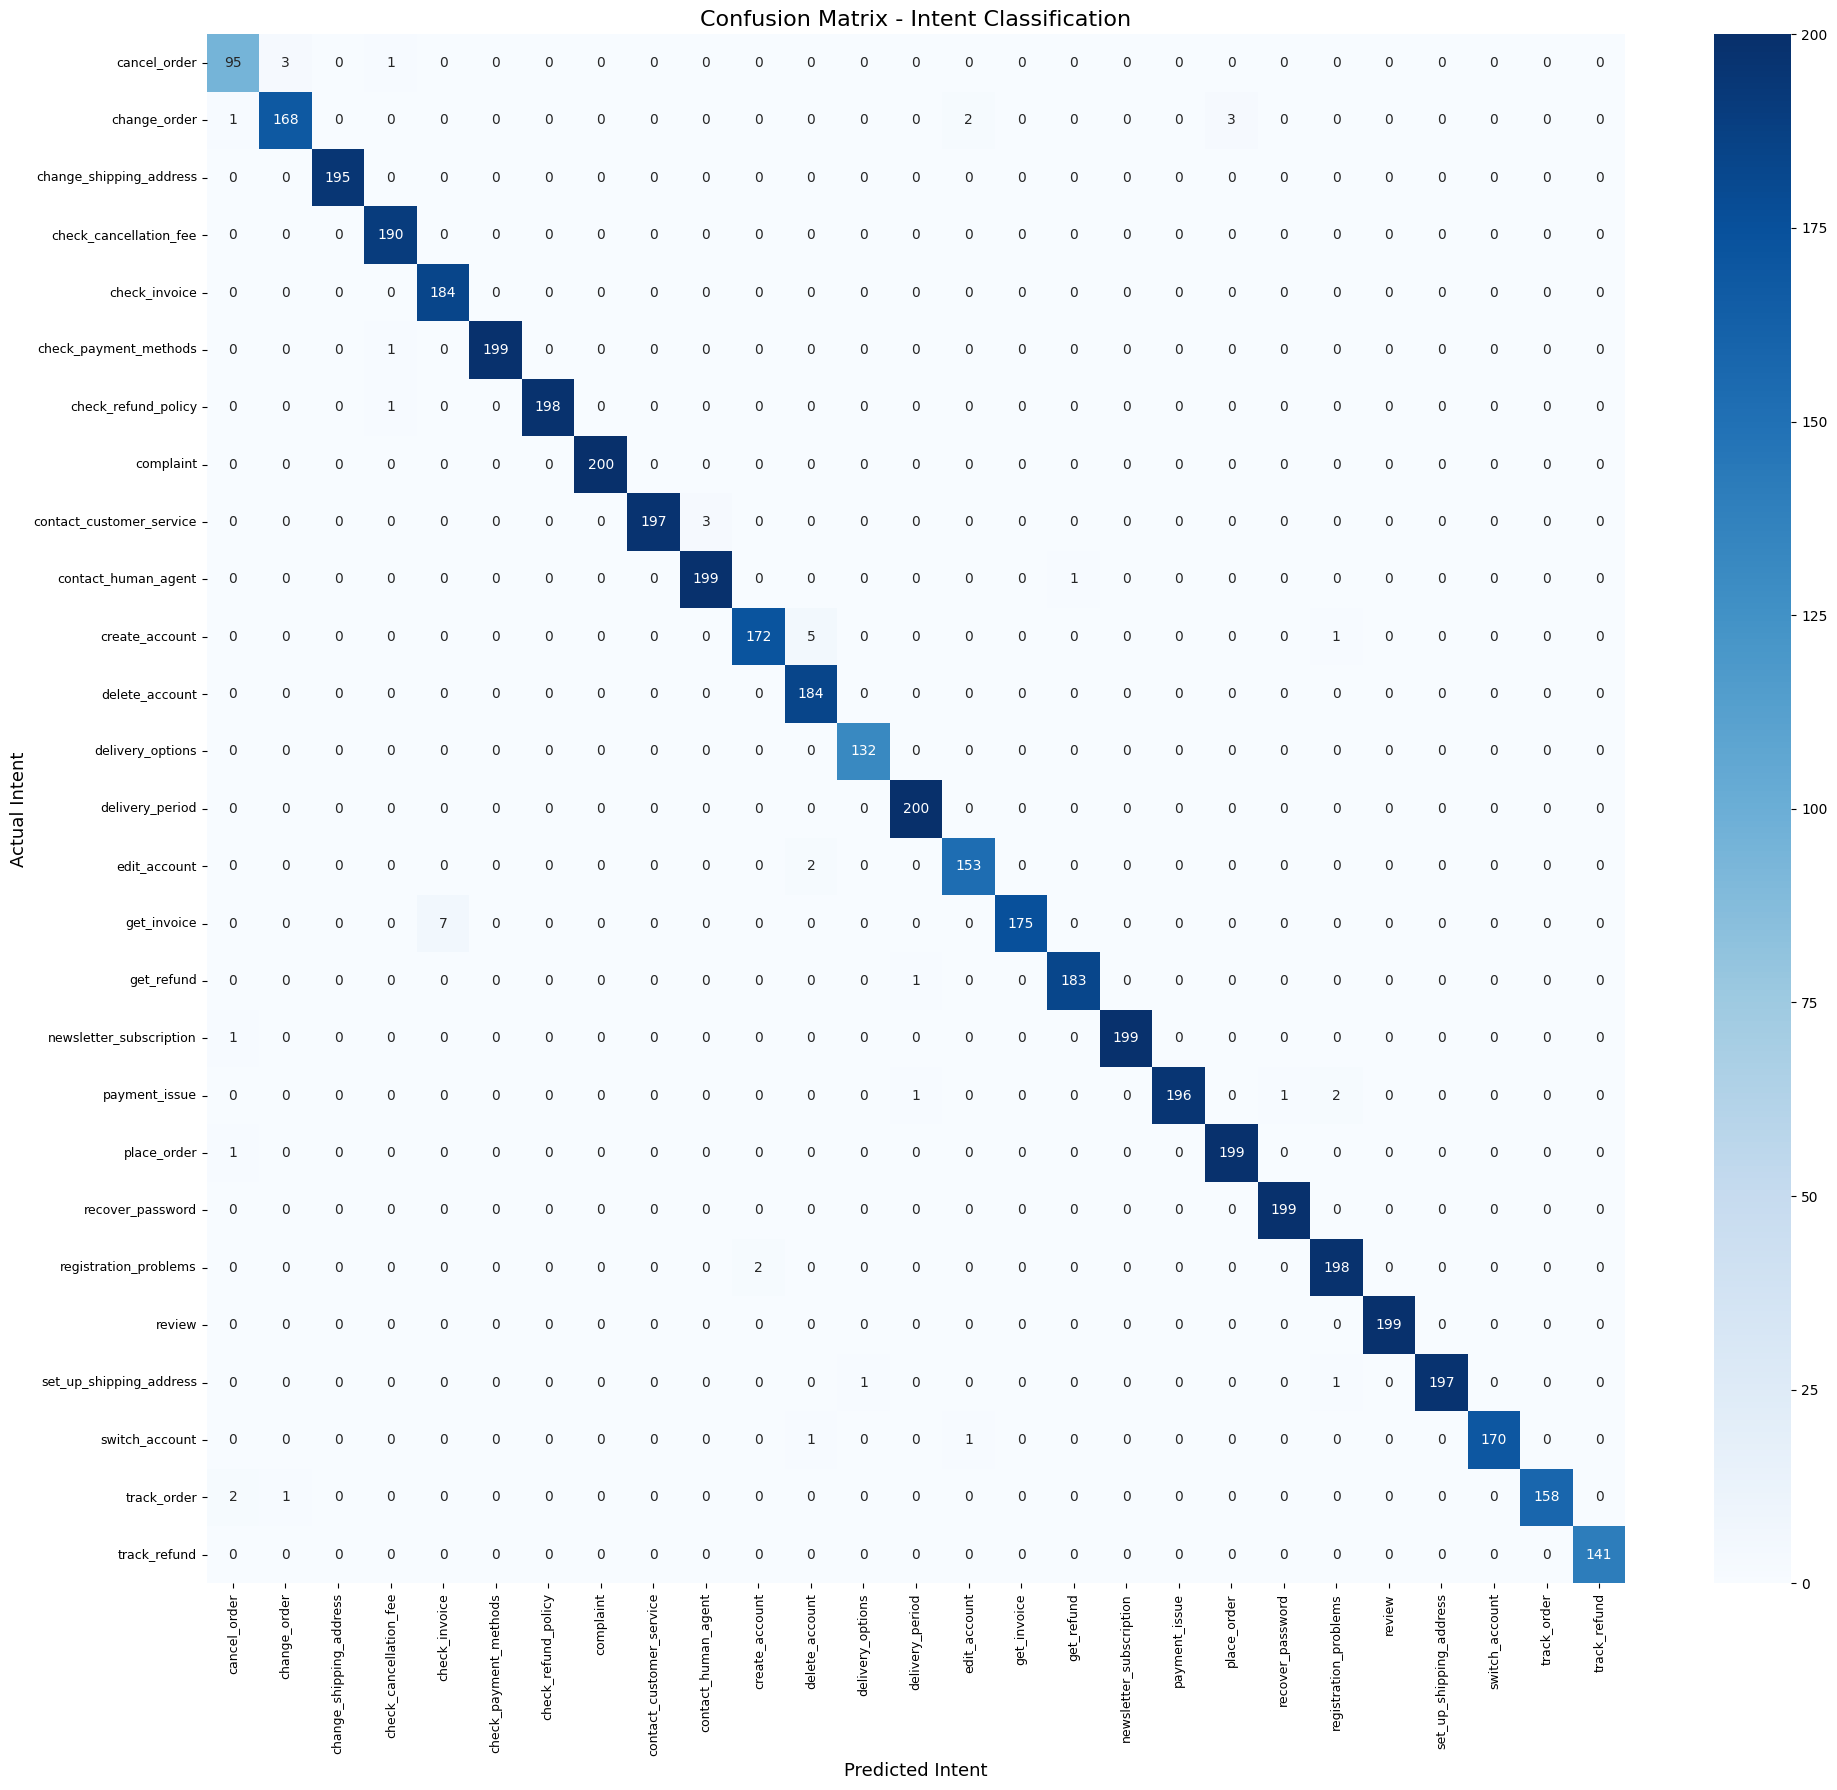

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=intent_model.classes_
)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_model.classes_,
    yticklabels=intent_model.classes_,
    cbar=True
)

plt.xlabel("Predicted Intent", fontsize=13)
plt.ylabel("Actual Intent", fontsize=13)
plt.title("Confusion Matrix - Intent Classification", fontsize=16)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

In [21]:
sentence = "I want to cancel my order"

prediction = intent_model.predict([sentence])[0]

print("Sentence:", sentence)
print("Predicted intent:", prediction)

Sentence: I want to cancel my order
Predicted intent: cancel_order


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
import os
import joblib

MODEL_DIR = "/content/drive/MyDrive/FogProject/Intent_Classification"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "intent_classifier.pkl"
)

In [24]:
joblib.dump(intent_model, MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /content/drive/MyDrive/FogProject/Intent_Classification/intent_classifier.pkl
